# TP ETL - Ingénierie des données

**Réalisés par :** Thierno-dtd

Fichier utilisé : `DonneesTP_ETL INGC2.xlsx`, feuille *Donnees_Brutes*.

In [112]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
import os

pd.set_option("display.max_columns", None)

# 1. Importation et exploration

In [ ]:
fichier = "DonneesTP_ETL.xlsx"
pd.ExcelFile(fichier).sheet_names

['Travail demandé', 'Donnees_Brutes']

In [114]:
pd.read_excel(fichier, sheet_name="Travail demandé")

,Odre,Partie
0,1,Importation et exploration
1,2,Doublons
2,3,Valeurs manquantes
3,4,Valeurs aberrantes
4,5,Nettoyage des données
5,6,Encodage
6,7,Transformation des dates
7,8,Création de variables
8,9,Visualisation
9,10,ETL complet + export


In [115]:
df_brut = pd.read_excel(fichier, sheet_name="Donnees_Brutes")
df = df_brut.copy()
df.head(10)

,Age,Revenu_Mensuel,Score_Service,Ville,Sexe,Statut_Professionnel,Client_Actif,Date_Inscription,Commentaire
0,34.0,429455.0,48.0,Libreville,Homme,Sans emploi,True,2023-05-31,Aucun commentaire
1,53.0,464545.0,43.0,Port-Gentil,Femme,Sans emploi,True,2024-07-16,À améliorer
2,39.0,86283.0,76.0,Lambaréné,Homme,Indépendant,False,2023-03-10,Aucun commentaire
3,130.0,203470.0,75.0,Port-Gentil,Homme,NaN,True,2025-10-19,Aucun commentaire
4,49.0,347708.0,57.0,Lambaréné,Homme,Etudiant,True,2025-04-26,Moyen
5,29.0,405983.0,80.0,Franceville,Femme,Sans emploi,False,2023-11-08,À améliorer
6,25.0,168583.0,94.0,Libreville,Homme,Indépendant,True,2024-08-23,Moyen
7,26.0,232760.0,59.0,Mouila,Homme,Sans emploi,False,2025-01-31,NaN
8,32.0,199420.0,92.0,Mouila,Homme,Employé,Oui,2023-06-11,NaN
9,34.0,193396.0,78.0,NaN,Homme,Indépendant,False,2024-08-27,Moyen


In [116]:
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

Nombre de lignes : 362
Nombre de colonnes : 9


In [117]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 362 entries, 0 to 361
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Age                   354 non-null    float64       
 1   Revenu_Mensuel        352 non-null    float64       
 2   Score_Service         355 non-null    float64       
 3   Ville                 356 non-null    str           
 4   Sexe                  357 non-null    str           
 5   Statut_Professionnel  356 non-null    str           
 6   Client_Actif          362 non-null    object        
 7   Date_Inscription      362 non-null    datetime64[us]
 8   Commentaire           353 non-null    str           
dtypes: datetime64[us](1), float64(3), object(1), str(4)
memory usage: 38.1+ KB


In [118]:
df.describe()

,Age,Revenu_Mensuel,Score_Service,Date_Inscription
count,354.000000,3.520000e+02,355.000000,362
mean,32.697740,4.076092e+05,69.281690,2024-08-24 00:27:50.718232
min,-5.000000,-2.000000e+05,-10.000000,2023-01-11 00:00:00
25%,26.000000,2.098182e+05,59.000000,2023-10-09 12:00:00
50%,33.000000,3.102765e+05,69.000000,2024-08-23 00:00:00
75%,37.000000,4.168322e+05,79.000000,2025-07-09 18:00:00
max,130.000000,1.200000e+07,200.000000,2026-08-01 00:00:00
std,11.041598,9.362523e+05,18.155778,NaN


In [119]:
df.nunique()

Age                      41
Revenu_Mensuel          330
Score_Service            70
Ville                    18
Sexe                      6
Statut_Professionnel      4
Client_Actif              4
Date_Inscription        304
Commentaire               5
dtype: int64

In [120]:
for col in ["Ville", "Sexe", "Statut_Professionnel", "Client_Actif", "Commentaire"]:
    print(df[col].value_counts(dropna=False))
    print("-" * 40)

Ville
Franceville     65
Mouila          63
Lambaréné       61
Libreville      56
Port-Gentil     51
Oyem            48
NaN              6
PORT-GENTIL      1
libreville       1
 Oyem            1
 LIBREVILLE      1
oyem             1
Franceville      1
FRANCEVILLE      1
lambaréné        1
MOUILA           1
LAMBARÉNÉ        1
port-gentil      1
mouila           1
Name: count, dtype: int64
----------------------------------------
Sexe
Femme      190
Homme      161
NaN          5
femme        2
homme        2
FEMME        1
 HOMME       1
Name: count, dtype: int64
----------------------------------------
Statut_Professionnel
Indépendant    106
Etudiant        86
Employé         84
Sans emploi     80
NaN              6
Name: count, dtype: int64
----------------------------------------
Client_Actif
False    186
True     168
Oui        4
Non        4
Name: count, dtype: int64
----------------------------------------
Commentaire
Moyen                74
Très satisfait       73
Satisfait     

**Ce qu'on remarque à l'exploration :**

- Le fichier contient 362 lignes et 9 colonnes.
- `Age` et `Score_Service` sont lus en `float` alors que ce sont des entiers.
- Le `describe()` montre déjà des valeurs impossibles : par exemple un âge minimum de -5 ans et maximum de 130 ans, un score qui va de -10 à 200 alors qu'il est noté sur 100, un revenu négatif (-200 000) et un revenu maximum de 12 000 000 alors que 75 % des clients gagnent moins de 420 000.
- l'attritut `Ville` a 18 modalités alors qu'il n'y a que 6 villes : la même ville est écrite en majuscules, en minuscules ou avec des espaces supplémentaires.
- Même REmarque pour l'attritut `Sexe` (`'femme'`, `'FEMME '`, `' HOMME '`).
- `Client_Actif` mélange des booléens (`True`/`False`) et du texte (`'Oui'`/`'Non'`).
- Il y a des valeurs manquantes dans presque toutes les colonnes sauf `Client_Actif` et `Date_Inscription`.

# 2. Doublons

In [121]:
print("Nombre de doublons :", df.duplicated().sum())

Nombre de doublons : 12


In [122]:
df[df.duplicated(keep=False)].sort_values(["Date_Inscription", "Revenu_Mensuel"])

,Age,Revenu_Mensuel,Score_Service,Ville,Sexe,Statut_Professionnel,Client_Actif,Date_Inscription,Commentaire
100,35.0,196260.0,70.0,Franceville,Femme,Sans emploi,False,2023-02-26,Très satisfait
236,35.0,196260.0,70.0,Franceville,Femme,Sans emploi,False,2023-02-26,Très satisfait
32,46.0,541140.0,59.0,Oyem,Femme,Indépendant,False,2023-06-19,À améliorer
197,46.0,541140.0,59.0,Oyem,Femme,Indépendant,False,2023-06-19,À améliorer
62,37.0,183142.0,69.0,Franceville,Homme,Employé,False,2023-10-08,Très satisfait
238,37.0,183142.0,69.0,Franceville,Homme,Employé,False,2023-10-08,Très satisfait
259,32.0,336804.0,77.0,Mouila,Homme,Employé,False,2023-12-27,Très satisfait
328,32.0,336804.0,77.0,Mouila,Homme,Employé,False,2023-12-27,Très satisfait
104,26.0,102907.0,69.0,Oyem,Homme,Etudiant,True,2024-01-16,Très satisfait
127,26.0,102907.0,69.0,Oyem,Homme,Etudiant,True,2024-01-16,Très satisfait


Nous remarquons la présence des doublons( exactement 12 lignes) deux à deux possedant eles meme valeur pour les attributs(même âge, même revenu au franc près, même date d'inscription, etc.). 

In [123]:
nb_avant = len(df)
df = df.drop_duplicates(keep="first").reset_index(drop=True)

print("Lignes avant :", nb_avant)
print("Lignes après :", len(df))
print("Doublons supprimés :", nb_avant - len(df))

Lignes avant : 362
Lignes après : 350
Doublons supprimés : 12


# 3. Valeurs manquantes

In [124]:
manquants = pd.DataFrame({
    "nb_manquants": df.isna().sum(),
    "pourcentage": (df.isna().mean() * 100).round(2)
})
manquants

,nb_manquants,pourcentage
Age,8,2.29
Revenu_Mensuel,10,2.86
Score_Service,7,2.00
Ville,6,1.71
Sexe,5,1.43
Statut_Professionnel,6,1.71
Client_Actif,0,0.00
Date_Inscription,0,0.00
Commentaire,8,2.29


In [125]:
lignes_na = df[df.isna().any(axis=1)]
print("Lignes avec au moins une valeur manquante :", len(lignes_na))
lignes_na.head(10)

Lignes avec au moins une valeur manquante : 47


,Age,Revenu_Mensuel,Score_Service,Ville,Sexe,Statut_Professionnel,Client_Actif,Date_Inscription,Commentaire
3,130.0,203470.0,75.0,Port-Gentil,Homme,NaN,True,2025-10-19,Aucun commentaire
7,26.0,232760.0,59.0,Mouila,Homme,Sans emploi,False,2025-01-31,NaN
8,32.0,199420.0,92.0,Mouila,Homme,Employé,Oui,2023-06-11,NaN
9,34.0,193396.0,78.0,NaN,Homme,Indépendant,False,2024-08-27,Moyen
16,37.0,NaN,86.0,Port-Gentil,Femme,Employé,False,2025-11-28,Moyen
20,NaN,479995.0,80.0,Port-Gentil,NaN,Etudiant,True,2025-02-15,Très satisfait
31,29.0,121848.0,NaN,Libreville,Homme,Sans emploi,False,2025-05-17,À améliorer
38,NaN,328432.0,100.0,Libreville,Femme,Etudiant,True,2026-01-12,Très satisfait
47,NaN,248598.0,63.0,Oyem,Homme,Sans emploi,False,2023-05-31,Très satisfait
61,18.0,310749.0,NaN,libreville,Femme,Etudiant,True,2024-04-07,À améliorer


présence des valeurs manquantes. ON procedera comme suit pour les corriger : 

- **Age, Revenu_Mensuel, Score_Service** : remplacement par la médiane. 
- **Ville, Sexe, Statut_Professionnel** : remplacement par le mode (la valeur la plus fréquente).
- **Commentaire** : une case vide veut juste dire que le client n'a rien écrit. On mettra `'Aucun commentaire'`, qui existe déjà dans la colonne.

In [126]:
print("Revenu moyen   :", round(df["Revenu_Mensuel"].mean()))
print("Revenu médian  :", df["Revenu_Mensuel"].median())

Revenu moyen   : 411809
Revenu médian  : 310276.5


In [127]:
df["Ville"].str.strip().str.title().value_counts().head(3)

Ville
Lambaréné      63
Mouila         63
Franceville    62
Name: count, dtype: int64

Lambaréné et Mouila sont à égalité avec 63 clients. Dans ce cas mode() renvoie les deux valeurs triées et on prend la première, Lambaréné. 

In [128]:
for col in ["Age", "Revenu_Mensuel", "Score_Service"]:
    mediane = df[col].median()
    print(f"{col} : {df[col].isna().sum()} valeurs remplacées par {mediane}")
    df[col] = df[col].fillna(mediane)

modes = {
    "Ville": df["Ville"].str.strip().str.title().mode()[0],
    "Sexe": df["Sexe"].str.strip().str.capitalize().mode()[0],
    "Statut_Professionnel": df["Statut_Professionnel"].mode()[0],
}
for col, mode in modes.items():
    print(f"{col} : {df[col].isna().sum()} valeurs remplacées par '{mode}'")
    df[col] = df[col].fillna(mode)

print(f"Commentaire : {df['Commentaire'].isna().sum()} valeurs remplacées par 'Aucun commentaire'")
df["Commentaire"] = df["Commentaire"].fillna("Aucun commentaire")

Age : 8 valeurs remplacées par 32.5
Revenu_Mensuel : 10 valeurs remplacées par 310276.5
Score_Service : 7 valeurs remplacées par 69.0
Ville : 6 valeurs remplacées par 'Lambaréné'
Sexe : 5 valeurs remplacées par 'Femme'
Statut_Professionnel : 6 valeurs remplacées par 'Indépendant'
Commentaire : 8 valeurs remplacées par 'Aucun commentaire'


In [129]:
df.isna().sum()

Age                     0
Revenu_Mensuel          0
Score_Service           0
Ville                   0
Sexe                    0
Statut_Professionnel    0
Client_Actif            0
Date_Inscription        0
Commentaire             0
dtype: int64

Plus aucune valeur manquante.

# 4. Valeurs aberrantes

 regardons d'abord la distribution des trois variables numériques avec des boîtes à moustaches.

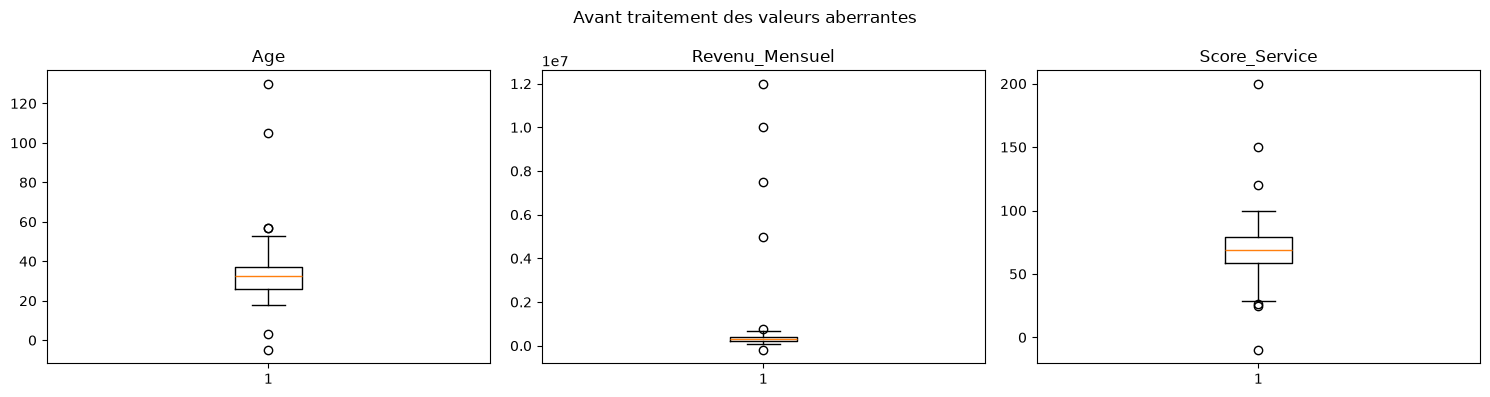

In [130]:
colonnes_num = ["Age", "Revenu_Mensuel", "Score_Service"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, colonnes_num):
    ax.boxplot(df[col])
    ax.set_title(col)
plt.suptitle("Avant traitement des valeurs aberrantes")
plt.tight_layout()
plt.show()

On détecte ensuite les valeurs aberrantes(la méthode de l'écart interquartile (IQR)) : une valeur est suspecte si elle est en dehors de la boite a moustashe

In [131]:
def bornes_iqr(serie, k=1.5):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

for col in colonnes_num:
    bas, haut = bornes_iqr(df[col])
    hors = df.loc[(df[col] < bas) | (df[col] > haut), col]
    print(f"{col} : bornes [{bas:.0f} ; {haut:.0f}] -> {len(hors)} valeurs : {sorted(hors.tolist())}")

Age : bornes [10 ; 54] -> 6 valeurs : [-5.0, 3.0, 57.0, 57.0, 105.0, 130.0]
Revenu_Mensuel : bornes [-83835 ; 715747] -> 6 valeurs : [-200000.0, 751043.0, 5000000.0, 7500000.0, 10000000.0, 12000000.0]
Score_Service : bornes [29 ; 109] -> 6 valeurs : [-10.0, 25.0, 26.0, 120.0, 150.0, 200.0]


L'IQR attrape bien les erreurs évidentes, mais il signale aussi des valeurs tout à fait possibles : deux clients de 57 ans, des scores de 25 et 26 sur 100, un revenu de 751 043 FCFA. La méthode ne connaît pas le sens des variables, elle regarde seulement la dispersion. Corriger ces valeurs-là ferait perdre de la vraie information.

J'ai donc combiné l'IQR avec des règles métier :

| Variable | Règle retenue | Justification |
|---|---|---|
| Age | entre 18 et 100 ans | ce sont des clients, donc des adultes ; -5 ans ou 130 ans est impossible |
| Score_Service | entre 0 et 100 | le score est une note sur 100 |
| Revenu_Mensuel | entre 0 et Q3 + 3×IQR | un revenu ne peut pas être négatif ; pour le haut j'utilise la barrière « extrême » de Tukey (k = 3) qui isole seulement les valeurs vraiment hors norme |


In [132]:
regles = {
    "Age": (18, 100),
    "Score_Service": (0, 100),
    "Revenu_Mensuel": (0, bornes_iqr(df["Revenu_Mensuel"], k=3)[1]),
}

for col, (bas, haut) in regles.items():
    masque = (df[col] < bas) | (df[col] > haut)
    print(f"{col} : {masque.sum()} valeurs aberrantes -> {sorted(df.loc[masque, col].tolist())}")

Age : 4 valeurs aberrantes -> [-5.0, 3.0, 105.0, 130.0]
Score_Service : 4 valeurs aberrantes -> [-10.0, 120.0, 150.0, 200.0]
Revenu_Mensuel : 5 valeurs aberrantes -> [-200000.0, 5000000.0, 7500000.0, 10000000.0, 12000000.0]


In [133]:
nb_aberrantes = {}
for col, (bas, haut) in regles.items():
    masque = (df[col] < bas) | (df[col] > haut)
    mediane = df.loc[~masque, col].median()
    df.loc[masque, col] = mediane
    nb_aberrantes[col] = int(masque.sum())
    print(f"{col} : {masque.sum()} valeurs remplacées par la médiane {mediane}")

Age : 4 valeurs remplacées par la médiane 32.5
Score_Service : 4 valeurs remplacées par la médiane 69.0
Revenu_Mensuel : 5 valeurs remplacées par la médiane 310276.5


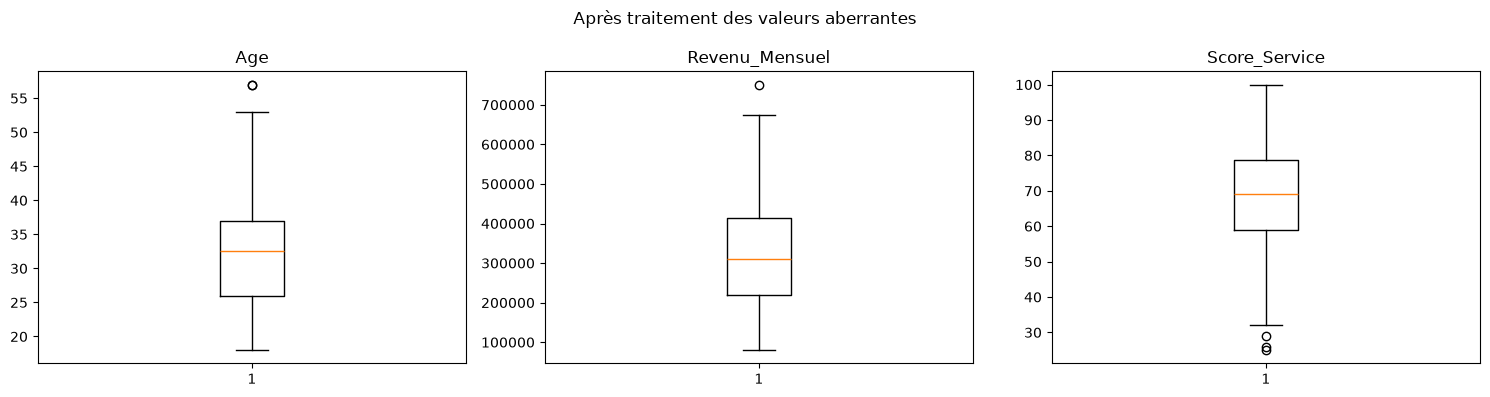

,Age,Revenu_Mensuel,Score_Service
count,350.000000,350.000000,350.000000
mean,32.317143,315340.661429,68.580000
std,8.445815,134439.574320,15.380863
min,18.000000,80000.000000,25.000000
25%,26.000000,218847.500000,59.000000
50%,32.500000,310276.500000,69.000000
75%,37.000000,413364.500000,78.750000
max,57.000000,751043.000000,100.000000


In [134]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, colonnes_num):
    ax.boxplot(df[col])
    ax.set_title(col)
plt.suptitle("Après traitement des valeurs aberrantes")
plt.tight_layout()
plt.show()

df[colonnes_num].describe()

Les boîtes à moustaches sont maintenant normal. Le revenu moyen passe de 411 809 à 315 341 FCFA et l'écart-type du revenu passe de plus de 930 000 à environ 134 000 : cinq valeurs fausses suffisaient à fausser toutes les statistiques.

# 5. Nettoyage des données

Harmonisation des données



In [135]:
print("Avant :", df["Ville"].nunique(), "villes,", df["Sexe"].nunique(), "modalités pour Sexe")

df["Ville"] = df["Ville"].str.strip().str.title()
df["Sexe"] = df["Sexe"].str.strip().str.capitalize()
df["Statut_Professionnel"] = df["Statut_Professionnel"].str.strip()
df["Commentaire"] = df["Commentaire"].str.strip()

print("Après :", df["Ville"].nunique(), "villes,", df["Sexe"].nunique(), "modalités pour Sexe")

Avant : 18 villes, 6 modalités pour Sexe
Après : 6 villes, 2 modalités pour Sexe


In [136]:
df["Client_Actif"] = df["Client_Actif"].map({True: True, False: False, "Oui": True, "Non": False})
print("Valeurs non reconnues :", df["Client_Actif"].isna().sum())
df["Client_Actif"] = df["Client_Actif"].astype(bool)

Valeurs non reconnues : 0


In [137]:
for col in colonnes_num:
    df[col] = df[col].round().astype(int)

In [138]:
for col in ["Ville", "Sexe", "Statut_Professionnel", "Client_Actif", "Commentaire"]:
    print(df[col].value_counts())
    print("-" * 40)

Ville
Lambaréné      69
Mouila         63
Franceville    62
Libreville     56
Port-Gentil    52
Oyem           48
Name: count, dtype: int64
----------------------------------------
Sexe
Femme    192
Homme    158
Name: count, dtype: int64
----------------------------------------
Statut_Professionnel
Indépendant    107
Etudiant        84
Employé         81
Sans emploi     78
Name: count, dtype: int64
----------------------------------------
Client_Actif
False    183
True     167
Name: count, dtype: int64
----------------------------------------
Commentaire
Aucun commentaire    75
Moyen                73
Satisfait            70
Très satisfait       67
À améliorer          65
Name: count, dtype: int64
----------------------------------------


Refaisons un controlde de doubons

In [139]:
print("Doublons après nettoyage :", df.duplicated().sum())

Doublons après nettoyage : 0


In [140]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Age                   350 non-null    int64         
 1   Revenu_Mensuel        350 non-null    int64         
 2   Score_Service         350 non-null    int64         
 3   Ville                 350 non-null    str           
 4   Sexe                  350 non-null    str           
 5   Statut_Professionnel  350 non-null    str           
 6   Client_Actif          350 non-null    bool          
 7   Date_Inscription      350 non-null    datetime64[us]
 8   Commentaire           350 non-null    str           
dtypes: bool(1), datetime64[us](1), int64(3), str(4)
memory usage: 34.7 KB


# 6. Encodage


Le choix de l'encodage dépend du type de variable :

- **Sexe** et **Client_Actif** n'ont que deux valeurs : encodage binaire 0/1.
- **Commentaire** a un ordre naturel (À améliorer < Moyen < Satisfait < Très satisfait) : encodage ordinal de 1 à 4. *Aucun commentaire* est mis à 0. 
- **Ville** et **Statut_Professionnel** n'ont pas d'ordre : encodage one-hot (`get_dummies`).

In [141]:
ordre_satisfaction = {
    "Aucun commentaire": 0,
    "À améliorer": 1,
    "Moyen": 2,
    "Satisfait": 3,
    "Très satisfait": 4,
}


def encoder(data):
    data = data.copy()
    data["Sexe"] = data["Sexe"].map({"Homme": 0, "Femme": 1})
    data["Client_Actif"] = data["Client_Actif"].astype(int)
    data["Sans_Commentaire"] = (data["Commentaire"] == "Aucun commentaire").astype(int)
    data["Commentaire"] = data["Commentaire"].map(ordre_satisfaction)
    data = pd.get_dummies(data, columns=["Ville", "Statut_Professionnel"],
                          prefix=["Ville", "Statut"], dtype=int)
    return data


df_encode = encoder(df)
df_encode.head()

,Age,Revenu_Mensuel,Score_Service,Sexe,Client_Actif,Date_Inscription,Commentaire,Sans_Commentaire,Ville_Franceville,Ville_Lambaréné,Ville_Libreville,Ville_Mouila,Ville_Oyem,Ville_Port-Gentil,Statut_Employé,Statut_Etudiant,Statut_Indépendant,Statut_Sans emploi
0,34,429455,48,0,1,2023-05-31,0,1,0,0,1,0,0,0,0,0,0,1
1,53,464545,43,1,1,2024-07-16,1,0,0,0,0,0,0,1,0,0,0,1
2,39,86283,76,0,0,2023-03-10,0,1,0,1,0,0,0,0,0,0,1,0
3,32,203470,75,0,1,2025-10-19,0,1,0,0,0,0,0,1,0,0,1,0
4,49,347708,57,0,1,2025-04-26,2,0,0,1,0,0,0,0,0,1,0,0


In [142]:
print("Colonnes avant encodage :", df.shape[1])
print("Colonnes après encodage :", df_encode.shape[1])
print("Valeurs non encodées :", df_encode.isna().sum().sum())

Colonnes avant encodage : 9
Colonnes après encodage : 18
Valeurs non encodées : 0


# 7. Transformation des dates

In [143]:
df["Date_Inscription"] = pd.to_datetime(df["Date_Inscription"], errors="coerce")

print("Type :", df["Date_Inscription"].dtype)
print("Dates invalides :", df["Date_Inscription"].isna().sum())
print("Première inscription :", df["Date_Inscription"].min().date())
print("Dernière inscription :", df["Date_Inscription"].max().date())

Type : datetime64[us]
Dates invalides : 0
Première inscription : 2023-01-11
Dernière inscription : 2026-08-01


 il faut une date de référence pour les calculs d'ancienneté

In [144]:
date_reference = pd.Timestamp("2026-10-06")
print("Inscriptions postérieures à la date de référence :", (df["Date_Inscription"] > date_reference).sum())

Inscriptions postérieures à la date de référence : 0


In [145]:
df["Date_Inscription"].dt.to_period("M").value_counts().sort_index().tail(8)

Date_Inscription
2025-10     7
2025-11     9
2025-12     6
2026-01    10
2026-02     8
2026-03     8
2026-04     3
2026-08     1
Freq: M, Name: count, dtype: int64

On extrait ensuite les éléments utiles de la date

In [146]:
mois_fr = {1: "Janvier", 2: "Février", 3: "Mars", 4: "Avril", 5: "Mai", 6: "Juin",
           7: "Juillet", 8: "Août", 9: "Septembre", 10: "Octobre", 11: "Novembre", 12: "Décembre"}
jours_fr = {0: "Lundi", 1: "Mardi", 2: "Mercredi", 3: "Jeudi", 4: "Vendredi", 5: "Samedi", 6: "Dimanche"}

df["Annee_Inscription"] = df["Date_Inscription"].dt.year
df["Mois_Inscription"] = df["Date_Inscription"].dt.month
df["Nom_Mois"] = df["Mois_Inscription"].map(mois_fr)
df["Trimestre"] = df["Date_Inscription"].dt.quarter
df["Jour_Semaine"] = df["Date_Inscription"].dt.dayofweek.map(jours_fr)

df[["Date_Inscription", "Annee_Inscription", "Mois_Inscription", "Nom_Mois", "Trimestre", "Jour_Semaine"]].head()

,Date_Inscription,Annee_Inscription,Mois_Inscription,Nom_Mois,Trimestre,Jour_Semaine
0,2023-05-31,2023,5,Mai,2,Mercredi
1,2024-07-16,2024,7,Juillet,3,Mardi
2,2023-03-10,2023,3,Mars,1,Vendredi
3,2025-10-19,2025,10,Octobre,4,Dimanche
4,2025-04-26,2025,4,Avril,2,Samedi


In [147]:
df["Annee_Inscription"].value_counts().sort_index()

Annee_Inscription
2023    114
2024     96
2025    110
2026     30
Name: count, dtype: int64

# 8. Création de variables

 pour l'analyse on utilisera les variable suivantes:

- `Anciennete_Jours` et `Anciennete_Mois` : depuis combien de temps le client est inscrit (par rapport à la date de référence).
- `Tranche_Age` : 18-25, 26-35, 36-45, 46 ans et plus.
- `Revenu_Annuel` : revenu mensuel × 12.
- `Tranche_Revenu` : découpage en trois groupes de même effectif (terciles) avec `qcut`, ce qui évite d'avoir une classe presque vide.
- `Niveau_Score` : Faible (< 50), Moyen (50 à 74), Bon (75 et plus).
- `Client_Satisfait` : 1 si le commentaire est *Satisfait* ou *Très satisfait*, 0 sinon.

In [148]:
def creer_variables(data, date_ref):
    data = data.copy()
    data["Anciennete_Jours"] = (date_ref - data["Date_Inscription"]).dt.days
    data["Anciennete_Mois"] = ((date_ref.year - data["Date_Inscription"].dt.year) * 12
                               + (date_ref.month - data["Date_Inscription"].dt.month))
    data["Tranche_Age"] = pd.cut(data["Age"], bins=[17, 25, 35, 45, 100],
                                 labels=["18-25", "26-35", "36-45", "46 et +"])
    data["Revenu_Annuel"] = data["Revenu_Mensuel"] * 12
    data["Tranche_Revenu"] = pd.qcut(data["Revenu_Mensuel"], q=3, labels=["Faible", "Moyen", "Élevé"])
    data["Niveau_Score"] = pd.cut(data["Score_Service"], bins=[0, 50, 75, 101], right=False,
                                  labels=["Faible", "Moyen", "Bon"])
    data["Client_Satisfait"] = data["Commentaire"].isin(["Satisfait", "Très satisfait"]).astype(int)
    for col in ["Tranche_Age", "Tranche_Revenu", "Niveau_Score"]:
        data[col] = data[col].astype(str)
    return data


df = creer_variables(df, date_reference)
df.head()

,Age,Revenu_Mensuel,Score_Service,Ville,Sexe,Statut_Professionnel,Client_Actif,Date_Inscription,Commentaire,Annee_Inscription,Mois_Inscription,Nom_Mois,Trimestre,Jour_Semaine,Anciennete_Jours,Anciennete_Mois,Tranche_Age,Revenu_Annuel,Tranche_Revenu,Niveau_Score,Client_Satisfait
0,34,429455,48,Libreville,Homme,Sans emploi,True,2023-05-31,Aucun commentaire,2023,5,Mai,2,Mercredi,1224,41,26-35,5153460,Élevé,Faible,0
1,53,464545,43,Port-Gentil,Femme,Sans emploi,True,2024-07-16,À améliorer,2024,7,Juillet,3,Mardi,812,27,46 et +,5574540,Élevé,Faible,0
2,39,86283,76,Lambaréné,Homme,Indépendant,False,2023-03-10,Aucun commentaire,2023,3,Mars,1,Vendredi,1306,43,36-45,1035396,Faible,Bon,0
3,32,203470,75,Port-Gentil,Homme,Indépendant,True,2025-10-19,Aucun commentaire,2025,10,Octobre,4,Dimanche,352,12,26-35,2441640,Faible,Bon,0
4,49,347708,57,Lambaréné,Homme,Etudiant,True,2025-04-26,Moyen,2025,4,Avril,2,Samedi,528,18,46 et +,4172496,Moyen,Moyen,0


In [149]:
ordres = {
    "Tranche_Age": ["18-25", "26-35", "36-45", "46 et +"],
    "Tranche_Revenu": ["Faible", "Moyen", "Élevé"],
    "Niveau_Score": ["Faible", "Moyen", "Bon"],
    "Client_Satisfait": [0, 1],
}
for col, ordre in ordres.items():
    print(df[col].value_counts().reindex(ordre))
    print("-" * 40)

Tranche_Age
18-25       81
26-35      157
36-45       82
46 et +     30
Name: count, dtype: int64
----------------------------------------
Tranche_Revenu
Faible    117
Moyen     116
Élevé     117
Name: count, dtype: int64
----------------------------------------
Niveau_Score
Faible     37
Moyen     196
Bon       117
Name: count, dtype: int64
----------------------------------------
Client_Satisfait
0    213
1    137
Name: count, dtype: int64
----------------------------------------


In [150]:
df.groupby("Tranche_Revenu")["Revenu_Mensuel"].agg(["min", "max", "count"]).sort_values("min")

,min,max,count
Tranche_Revenu,,,
Faible,80000,248430,117
Moyen,248598,368503,116
Élevé,368661,751043,117


Maintenant que toutes les colonnes sont créées, on refait l'encodage sur le jeu complet.

In [151]:
df_encode = encoder(df)
df_encode = pd.get_dummies(df_encode, columns=["Tranche_Age", "Tranche_Revenu", "Niveau_Score"], dtype=int)
df_encode = df_encode.drop(columns=["Nom_Mois", "Jour_Semaine"])
print(df_encode.shape)
df_encode.head()

(350, 35)


,Age,Revenu_Mensuel,Score_Service,Sexe,Client_Actif,Date_Inscription,Commentaire,Annee_Inscription,Mois_Inscription,Trimestre,Anciennete_Jours,Anciennete_Mois,Revenu_Annuel,Client_Satisfait,Sans_Commentaire,Ville_Franceville,Ville_Lambaréné,Ville_Libreville,Ville_Mouila,Ville_Oyem,Ville_Port-Gentil,Statut_Employé,Statut_Etudiant,Statut_Indépendant,Statut_Sans emploi,Tranche_Age_18-25,Tranche_Age_26-35,Tranche_Age_36-45,Tranche_Age_46 et +,Tranche_Revenu_Faible,Tranche_Revenu_Moyen,Tranche_Revenu_Élevé,Niveau_Score_Bon,Niveau_Score_Faible,Niveau_Score_Moyen
0,34,429455,48,0,1,2023-05-31,0,2023,5,2,1224,41,5153460,0,1,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,1,0
1,53,464545,43,1,1,2024-07-16,1,2024,7,3,812,27,5574540,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,1,0,1,0
2,39,86283,76,0,0,2023-03-10,0,2023,3,1,1306,43,1035396,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,1,0,0
3,32,203470,75,0,1,2025-10-19,0,2025,10,4,352,12,2441640,0,1,0,0,0,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0
4,49,347708,57,0,1,2025-04-26,2,2025,4,2,528,18,4172496,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,1


# 9. Visualisation

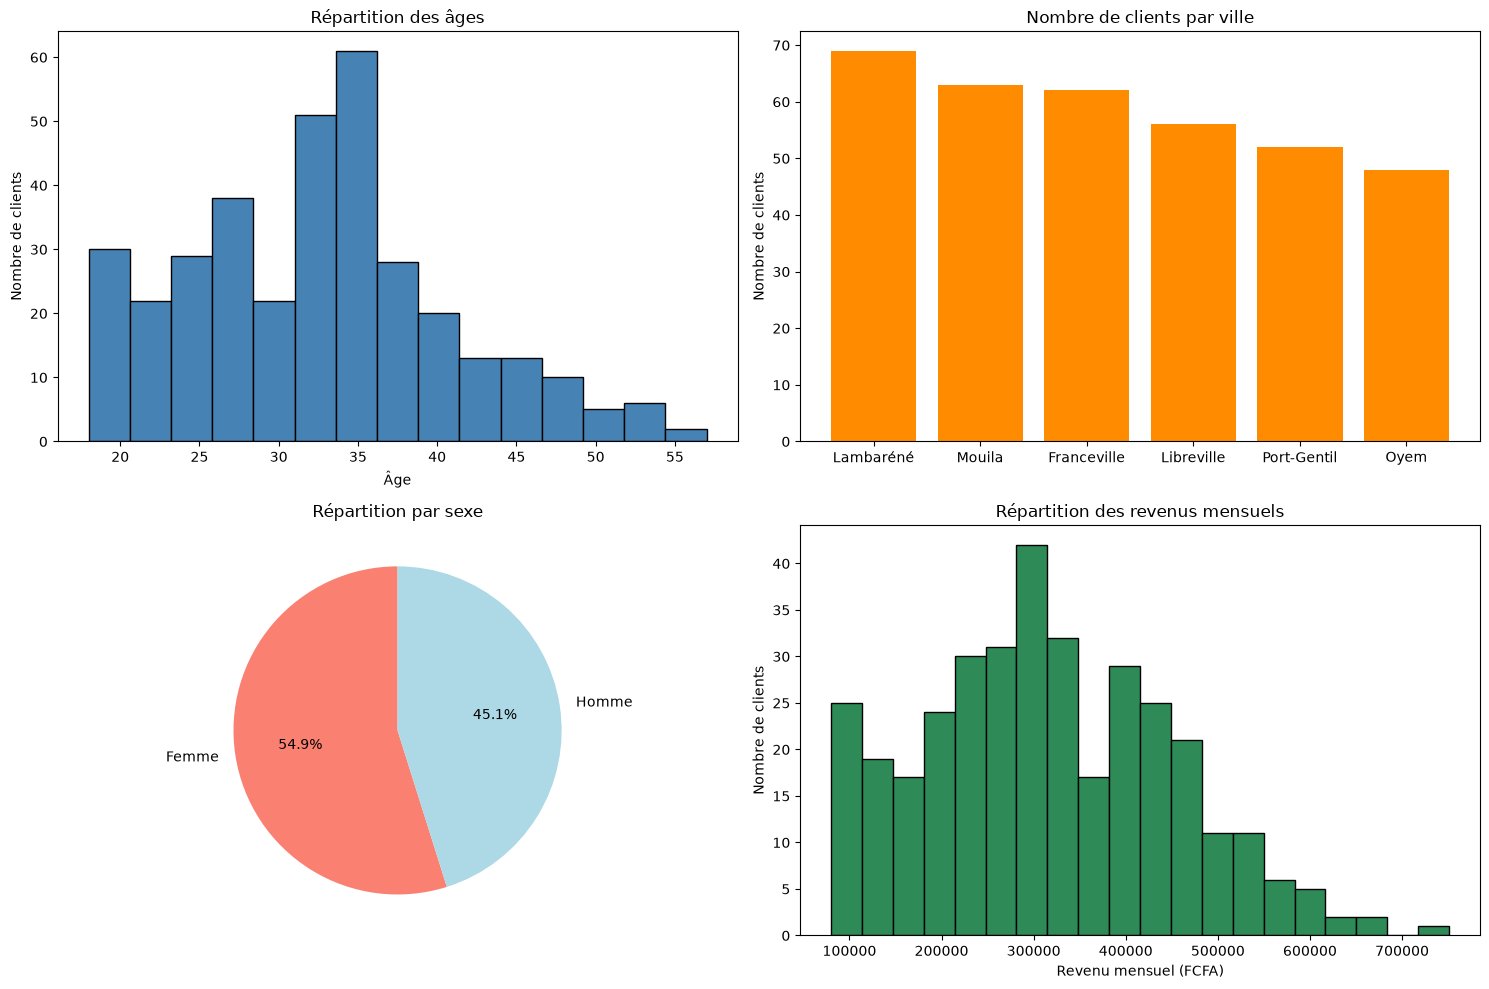

In [152]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes[0, 0].hist(df["Age"], bins=15, color="steelblue", edgecolor="black")
axes[0, 0].set_title("Répartition des âges")
axes[0, 0].set_xlabel("Âge")
axes[0, 0].set_ylabel("Nombre de clients")

clients_ville = df["Ville"].value_counts()
axes[0, 1].bar(clients_ville.index, clients_ville.values, color="darkorange")
axes[0, 1].set_title("Nombre de clients par ville")
axes[0, 1].set_ylabel("Nombre de clients")

sexe = df["Sexe"].value_counts()
axes[1, 0].pie(sexe, labels=sexe.index, autopct="%1.1f%%", startangle=90, colors=["salmon", "lightblue"])
axes[1, 0].set_title("Répartition par sexe")

axes[1, 1].hist(df["Revenu_Mensuel"], bins=20, color="seagreen", edgecolor="black")
axes[1, 1].set_title("Répartition des revenus mensuels")
axes[1, 1].set_xlabel("Revenu mensuel (FCFA)")
axes[1, 1].set_ylabel("Nombre de clients")

plt.tight_layout()
plt.show()

- La clientèle est jeune : la moitié des clients a entre 26 et 37 ans et personne n'a plus de 57 ans. 
- Les clients sont assez bien répartis entre les 6 villes, de 48 à Oyem jusqu'à 69 à Lambaréné.
- Il y a un peu plus de femmes (54,9 %) que d'hommes (45,1 %).
- Les revenus vont de 80 000 à 751 043 FCFA, avec une médiane autour de 310 000. Là aussi, la barre la plus haute vers 300 000 vient en partie des 15 revenus remplacés par la médiane. On remarque aussi que 11 clients ont exactement 80 000 FCFA, ce qui ressemble à un minimum

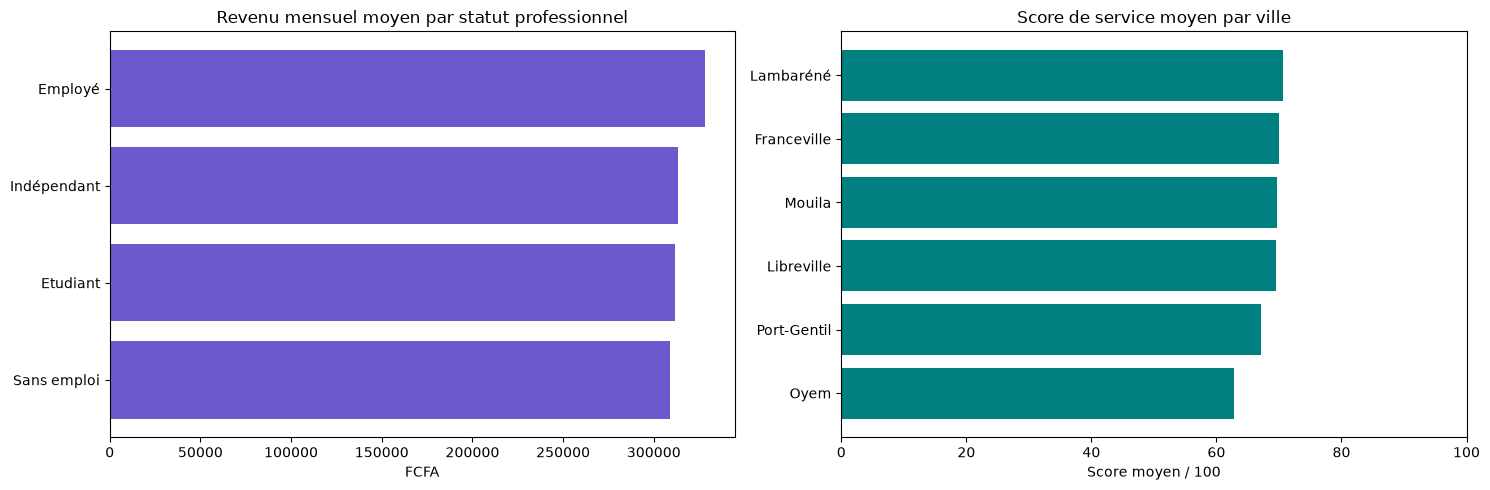

Statut_Professionnel
Sans emploi    308901.0
Etudiant       311640.0
Indépendant    313123.0
Employé        328308.0
Name: Revenu_Mensuel, dtype: float64

Ville
Oyem           62.8
Port-Gentil    67.1
Libreville     69.5
Mouila         69.7
Franceville    70.0
Lambaréné      70.7
Name: Score_Service, dtype: float64


In [153]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

revenu_statut = df.groupby("Statut_Professionnel")["Revenu_Mensuel"].mean().sort_values()
axes[0].barh(revenu_statut.index, revenu_statut.values, color="slateblue")
axes[0].set_title("Revenu mensuel moyen par statut professionnel")
axes[0].set_xlabel("FCFA")

score_ville = df.groupby("Ville")["Score_Service"].mean().sort_values()
axes[1].barh(score_ville.index, score_ville.values, color="teal")
axes[1].set_title("Score de service moyen par ville")
axes[1].set_xlim(0, 100)
axes[1].set_xlabel("Score moyen / 100")

plt.tight_layout()
plt.show()

print(revenu_statut.round())
print()
print(score_ville.round(1))

J'ai d'abord tracé la médiane du revenu par statut, mais pour les étudiants et les indépendants elle tombait pile sur 310 276 FCFA.

Les écarts entre statuts sont faibles : de 308 901 FCFA pour les sans emploi à 328 308 FCFA pour les employés.

Pour le score de service, toutes les villes sont entre 67 et 71 sur 100, sauf Oyem qui décroche nettement à 62,8. 

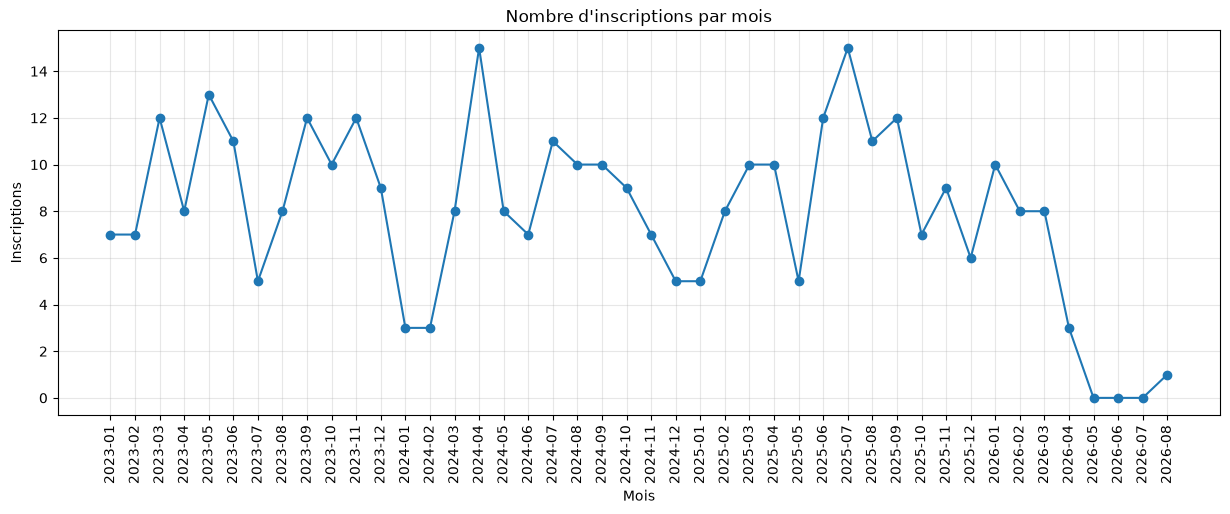

In [154]:
inscriptions = df.groupby(df["Date_Inscription"].dt.to_period("M")).size()
tous_les_mois = pd.period_range(inscriptions.index.min(), inscriptions.index.max(), freq="M")
inscriptions = inscriptions.reindex(tous_les_mois, fill_value=0)

plt.figure(figsize=(15, 5))
plt.plot(inscriptions.index.astype(str), inscriptions.values, marker="o")
plt.title("Nombre d'inscriptions par mois")
plt.xlabel("Mois")
plt.ylabel("Inscriptions")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.show()

Sur 2023-2025 le rythme est d'environ 8 à 9 inscriptions par mois, sans vraie tendance à la hausse ou à la baisse. Il y a des creux (janvier-février 2024, décembre 2024-janvier 2025) et des pics (avril 2024 et juillet 2025 avec 15 inscriptions). En 2026 par contre les inscriptions chutent après mars : 3 en avril, aucune de mai à juillet, puis une seule en août. 

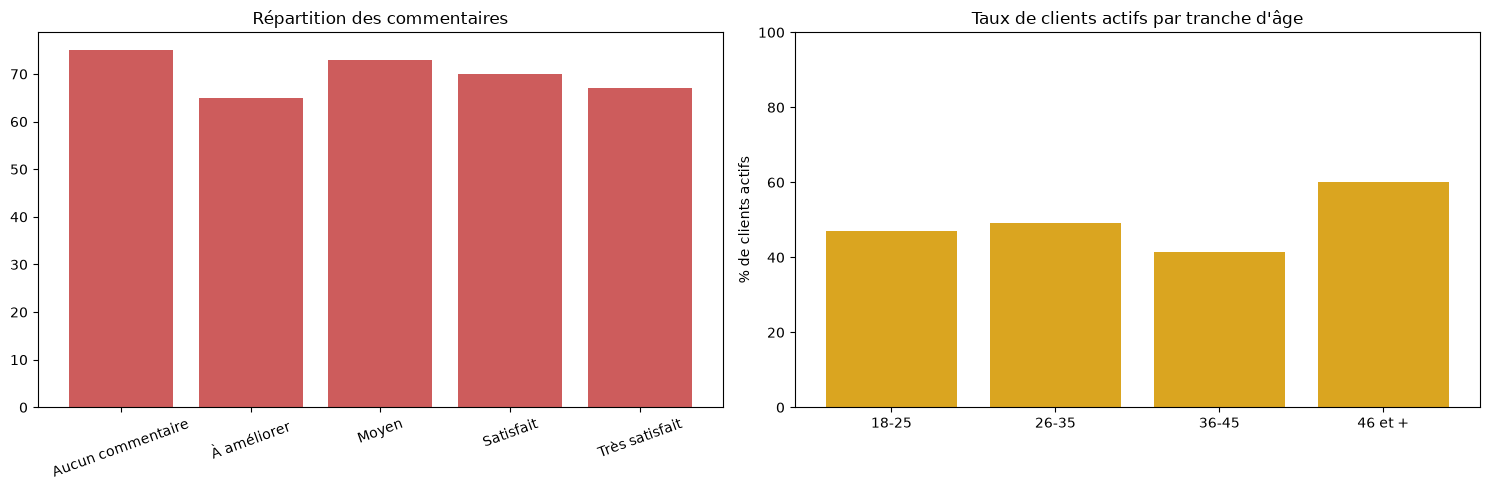

Tranche_Age
18-25      46.9
26-35      49.0
36-45      41.5
46 et +    60.0
Name: Client_Actif, dtype: float64


In [155]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

satisfaction = df["Commentaire"].value_counts().reindex(list(ordre_satisfaction.keys()))
axes[0].bar(satisfaction.index, satisfaction.values, color="indianred")
axes[0].set_title("Répartition des commentaires")
axes[0].tick_params(axis="x", rotation=20)

actifs_age = df.groupby("Tranche_Age")["Client_Actif"].mean() * 100
axes[1].bar(actifs_age.index, actifs_age.values, color="goldenrod")
axes[1].set_title("Taux de clients actifs par tranche d'âge")
axes[1].set_ylabel("% de clients actifs")
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

print(actifs_age.round(1))

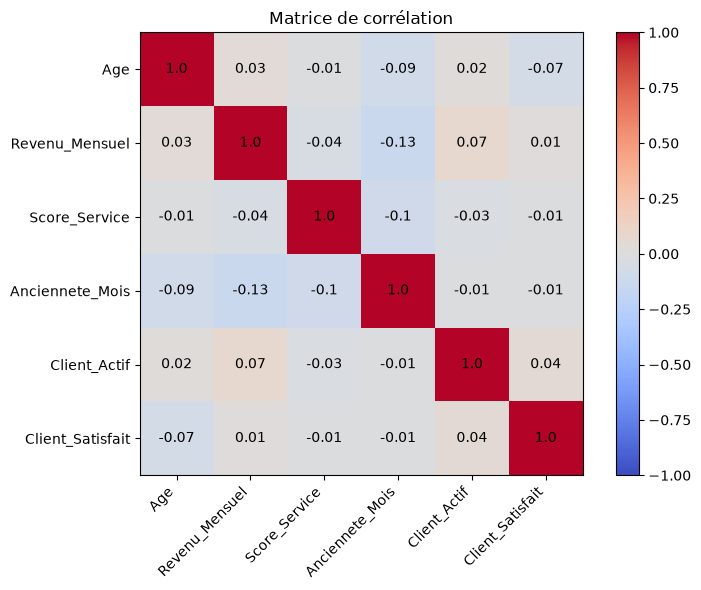

In [156]:
variables = ["Age", "Revenu_Mensuel", "Score_Service", "Anciennete_Mois", "Client_Actif", "Client_Satisfait"]
corr = df[variables].astype(float).corr()

plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(variables)), variables, rotation=45, ha="right")
plt.yticks(range(len(variables)), variables)
for i in range(len(variables)):
    for j in range(len(variables)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha="center", va="center")
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

Toutes les corrélations sont proches de 0, la plus forte est seulement -0,13 entre le revenu et l'ancienneté. Il n'y a donc pas de relation linéaire entre ces variables : l'âge ou le revenu n'expliquent ni le score de service, ni le fait d'être actif.

In [157]:
df.groupby("Commentaire")["Score_Service"].mean().round(1).reindex(list(ordre_satisfaction.keys()))

Commentaire
Aucun commentaire    67.5
À améliorer          70.0
Moyen                68.9
Satisfait            68.2
Très satisfait       68.4
Name: Score_Service, dtype: float64

# 10. ETL complet + export

On regroupe tout le traitement dans trois fonctions, une par étape de l'ETL. 
- **Extraire** : lecture du fichier Excel.
- **Transformer** : doublons, valeurs manquantes, valeurs aberrantes, nettoyage, dates, nouvelles variables, encodage. Chaque étape alimente un rapport qualité.
- **Charger** : export en CSV, en Excel (plusieurs feuilles) et dans une base SQLite.

In [158]:
def extraire(chemin, feuille="Donnees_Brutes"):
    data = pd.read_excel(chemin, sheet_name=feuille)
    print(f"Extraction : {len(data)} lignes, {data.shape[1]} colonnes")
    return data


def transformer(data, date_ref):
    data = data.copy()
    rapport = [("Lignes brutes", len(data))]

    nb = data.duplicated().sum()
    data = data.drop_duplicates().reset_index(drop=True)
    rapport.append(("Doublons supprimés", nb))

    rapport.append(("Valeurs manquantes traitées", data.isna().sum().sum()))
    for col in ["Age", "Revenu_Mensuel", "Score_Service"]:
        data[col] = data[col].fillna(data[col].median())
    data["Ville"] = data["Ville"].fillna(data["Ville"].str.strip().str.title().mode()[0])
    data["Sexe"] = data["Sexe"].fillna(data["Sexe"].str.strip().str.capitalize().mode()[0])
    data["Statut_Professionnel"] = data["Statut_Professionnel"].fillna(data["Statut_Professionnel"].mode()[0])
    data["Commentaire"] = data["Commentaire"].fillna("Aucun commentaire")

    bornes = {
        "Age": (18, 100),
        "Score_Service": (0, 100),
        "Revenu_Mensuel": (0, bornes_iqr(data["Revenu_Mensuel"], k=3)[1]),
    }
    for col, (bas, haut) in bornes.items():
        masque = (data[col] < bas) | (data[col] > haut)
        data.loc[masque, col] = data.loc[~masque, col].median()
        rapport.append((f"Valeurs aberrantes corrigées ({col})", masque.sum()))

    villes_avant = data["Ville"].nunique()
    data["Ville"] = data["Ville"].str.strip().str.title()
    data["Sexe"] = data["Sexe"].str.strip().str.capitalize()
    data["Statut_Professionnel"] = data["Statut_Professionnel"].str.strip()
    data["Commentaire"] = data["Commentaire"].str.strip()
    data["Client_Actif"] = data["Client_Actif"].map({True: True, False: False, "Oui": True, "Non": False}).astype(bool)
    for col in ["Age", "Revenu_Mensuel", "Score_Service"]:
        data[col] = data[col].round().astype(int)
    rapport.append(("Variantes d'écriture de villes corrigées",villes_avant - data["Ville"].nunique()))

    data["Date_Inscription"] = pd.to_datetime(data["Date_Inscription"], errors="coerce")
    data["Annee_Inscription"] = data["Date_Inscription"].dt.year
    data["Mois_Inscription"] = data["Date_Inscription"].dt.month
    data["Nom_Mois"] = data["Mois_Inscription"].map(mois_fr)
    data["Trimestre"] = data["Date_Inscription"].dt.quarter
    data["Jour_Semaine"] = data["Date_Inscription"].dt.dayofweek.map(jours_fr)

    data = creer_variables(data, date_ref)

    data_encode = encoder(data)
    data_encode = pd.get_dummies(data_encode, columns=["Tranche_Age", "Tranche_Revenu", "Niveau_Score"], dtype=int)
    data_encode = data_encode.drop(columns=["Nom_Mois", "Jour_Semaine"])

    rapport.append(("Lignes finales", len(data)))
    rapport.append(("Colonnes jeu propre", data.shape[1]))
    rapport.append(("Colonnes jeu encodé", data_encode.shape[1]))
    rapport = pd.DataFrame(rapport, columns=["Indicateur", "Valeur"])
    rapport["Valeur"] = rapport["Valeur"].astype(int)
    return data, data_encode, rapport


def charger(data, data_encode, rapport, dossier="sortie"):
    os.makedirs(dossier, exist_ok=True)

    data.to_csv(f"{dossier}/clients_propres.csv", index=False, sep=";", encoding="utf-8-sig")
    data_encode.to_csv(f"{dossier}/clients_encodes.csv", index=False, sep=";", encoding="utf-8-sig")

    with pd.ExcelWriter(f"{dossier}/clients_ETL.xlsx") as writer:
        data.to_excel(writer, sheet_name="Donnees_Propres", index=False)
        data_encode.to_excel(writer, sheet_name="Donnees_Encodees", index=False)
        rapport.to_excel(writer, sheet_name="Rapport_Qualite", index=False)

    bdd = sqlite3.connect(f"{dossier}/clients.db")
    data.to_sql("clients", bdd, if_exists="replace", index=False)
    data_encode.to_sql("clients_encodes", bdd, if_exists="replace", index=False)
    bdd.close()

    print("Fichiers créés dans le dossier", dossier, ":")
    for f in sorted(os.listdir(dossier)):
        print("  -", f)

In [159]:
donnees = extraire("DonneesTP_ETL INGC2.xlsx")
df_final, df_final_encode, rapport = transformer(donnees, pd.Timestamp("2026-10-06"))
charger(df_final, df_final_encode, rapport)

Extraction : 362 lignes, 9 colonnes
Fichiers créés dans le dossier sortie :
  - clients.db
  - clients_ETL.xlsx
  - clients_encodes.csv
  - clients_propres.csv


### Contrôles qualité
 vérifions que le jeu final respecte toutes les règles fixées dans le TP, et que le pipeline donne exactement le même résultat que le traitement fait pas à pas dans les parties 1 à 9.

In [160]:
assert df_final.isna().sum().sum() == 0, "il reste des valeurs manquantes"
assert df_final.duplicated().sum() == 0, "il reste des doublons"
assert df_final["Age"].between(18, 100).all(), "âge hors limites"
assert df_final["Score_Service"].between(0, 100).all(), "score hors limites"
assert (df_final["Revenu_Mensuel"] >= 0).all(), "revenu négatif"
assert df_final["Ville"].nunique() == 6, "villes mal harmonisées"
assert set(df_final["Sexe"]) == {"Homme", "Femme"}, "sexe mal harmonisé"
assert df_final["Client_Actif"].dtype == bool, "Client_Actif n'est pas booléen"
assert df_final.equals(df), "le pipeline ne donne pas le même résultat que le pas à pas"
assert df_final_encode.equals(df_encode), "l'encodage du pipeline est différent"

print("Tous les contrôles sont OK")

Tous les contrôles sont OK


### Vérification des fichiers exportés

On relit les fichiers produits pour s'assurer que l'export s'est bien passé.

In [161]:
verif_csv = pd.read_csv("sortie/clients_propres.csv", sep=";")
print("CSV :", verif_csv.shape)

verif_excel = pd.read_excel("sortie/clients_ETL.xlsx", sheet_name=None)
for feuille, contenu in verif_excel.items():
    print("Excel -", feuille, ":", contenu.shape)

CSV : (350, 21)
Excel - Donnees_Propres : (350, 21)
Excel - Donnees_Encodees : (350, 35)
Excel - Rapport_Qualite : (10, 2)


In [162]:
bdd = sqlite3.connect("sortie/clients.db")

sql = """
SELECT Ville,
       COUNT(*) AS nb_clients,
       ROUND(AVG(Revenu_Mensuel)) AS revenu_moyen,
       ROUND(AVG(Score_Service), 1) AS score_moyen,
       SUM(Client_Actif) AS nb_actifs
FROM clients
GROUP BY Ville
ORDER BY nb_clients DESC
"""
pd.read_sql(sql, bdd)

,Ville,nb_clients,revenu_moyen,score_moyen,nb_actifs
0,Lambaréné,69,337774.0,70.7,32
1,Mouila,63,317977.0,69.7,37
2,Franceville,62,296336.0,70.0,30
3,Libreville,56,314069.0,69.5,19
4,Port-Gentil,52,304817.0,67.1,26
5,Oyem,48,317065.0,62.8,23


In [163]:
bdd.close()